# Análisis del embudo de conversión y experimento A/A/B

### Análisis del comportamiento de usuarios en una aplicación de productos alimenticios

## Objetivo

Analizar el comportamiento de los usuarios dentro de una aplicación de productos alimenticios para identificar posibles puntos de abandono en el proceso de compra y evaluar mediante un experimento A/A/B si un cambio en las fuentes tipográficas afecta el comportamiento y la conversión de los usuarios.

## Herramientas utilizadas

- Python
- Pandas
- Matplotlib
- SciPy
- Statsmodels
- Pruebas Z de proporciones
- Corrección de Bonferroni
- Jupyter Notebook

## Análisis realizado

El proyecto incluye preparación y limpieza de datos, análisis exploratorio, construcción de un embudo de conversión, evaluación de las tasas de avance entre etapas y análisis estadístico de un experimento A/A/B mediante pruebas de hipótesis.

## 1. Importación y exploración inicial de los datos

In [ ]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest

Comenzamos importando las librerías requeridas para el desarrollo del proyecto.

In [ ]:
eventos = pd.read_csv('logs_exp_us.csv')

eventos.info()
print()
print(eventos.head())

<class 'pandas.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 1 columns):
 #   Column                                       Non-Null Count   Dtype
---  ------                                       --------------   -----
 0   EventName	DeviceIDHash	EventTimestamp	ExpId  244126 non-null  str  
dtypes: str(1)
memory usage: 953.7 KB

      EventName\tDeviceIDHash\tEventTimestamp\tExpId
0  MainScreenAppear\t4575588528974610257\t1564029...
1  MainScreenAppear\t7416695313311560658\t1564053...
2  PaymentScreenSuccessful\t3518123091307005509\t...
3  CartScreenAppear\t3518123091307005509\t1564054...
4  PaymentScreenSuccessful\t6217807653094995999\t...


Importamos el dataset y aplicamos .info() y .head() para conocer la estructura de los datos.

In [ ]:
eventos = pd.read_csv('logs_exp_us.csv', sep='\t')

eventos.info()
print()
print(eventos.head())

<class 'pandas.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   EventName       244126 non-null  str  
 1   DeviceIDHash    244126 non-null  int64
 2   EventTimestamp  244126 non-null  int64
 3   ExpId           244126 non-null  int64
dtypes: int64(3), str(1)
memory usage: 6.5 MB

                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248


Debido a que los datos están delimitados por tabulaciones, utilizamos el parámetro sep="\t" para estructurar las columnas de forma correcta. Posteriormente, volvemos a aplicar los métodos de inspección para confirmar que el DataFrame se separó adecuadamente.

## 2. Preparación y limpieza de los datos

In [ ]:
eventos.columns = ['nombre_evento', 'id_dispositivo', 'momento_evento', 'id_experimento']

eventos.info()

<class 'pandas.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   nombre_evento   244126 non-null  str  
 1   id_dispositivo  244126 non-null  int64
 2   momento_evento  244126 non-null  int64
 3   id_experimento  244126 non-null  int64
dtypes: int64(3), str(1)
memory usage: 6.5 MB


Se modificaron los nombres de las columnas a sus términos equivalentes en español (utilizando formato snake_case) para facilitar la lectura y escritura del código durante el proyecto.

In [ ]:
print(eventos.duplicated().sum())
print()

eventos = eventos.drop_duplicates()

print(eventos.duplicated().sum())
print()


eventos['momento_evento'] = pd.to_datetime(eventos['momento_evento'], unit='s')

eventos.info()
print()
print(eventos.head())

413

0

<class 'pandas.DataFrame'>
Index: 243713 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype        
---  ------          --------------   -----        
 0   nombre_evento   243713 non-null  str          
 1   id_dispositivo  243713 non-null  int64        
 2   momento_evento  243713 non-null  datetime64[s]
 3   id_experimento  243713 non-null  int64        
dtypes: datetime64[s](1), int64(2), str(1)
memory usage: 8.4 MB

             nombre_evento       id_dispositivo      momento_evento  \
0         MainScreenAppear  4575588528974610257 2019-07-25 04:43:36   
1         MainScreenAppear  7416695313311560658 2019-07-25 11:11:42   
2  PaymentScreenSuccessful  3518123091307005509 2019-07-25 11:28:47   
3         CartScreenAppear  3518123091307005509 2019-07-25 11:28:47   
4  PaymentScreenSuccessful  6217807653094995999 2019-07-25 11:48:42   

   id_experimento  
0             246  
1             246  
2             248  
3             

Se identificaron y eliminaron 413 filas duplicadas mediante el método .drop_duplicates(). Adicionalmente, se transformó la columna momento_evento de enteros a formato fecha y hora (datetime).

In [ ]:
eventos['fecha'] = eventos['momento_evento'].dt.date

eventos.info()
print()
print(eventos.head())

<class 'pandas.DataFrame'>
Index: 243713 entries, 0 to 244125
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype        
---  ------          --------------   -----        
 0   nombre_evento   243713 non-null  str          
 1   id_dispositivo  243713 non-null  int64        
 2   momento_evento  243713 non-null  datetime64[s]
 3   id_experimento  243713 non-null  int64        
 4   fecha           243713 non-null  object       
dtypes: datetime64[s](1), int64(2), object(1), str(1)
memory usage: 9.3+ MB

             nombre_evento       id_dispositivo      momento_evento  \
0         MainScreenAppear  4575588528974610257 2019-07-25 04:43:36   
1         MainScreenAppear  7416695313311560658 2019-07-25 11:11:42   
2  PaymentScreenSuccessful  3518123091307005509 2019-07-25 11:28:47   
3         CartScreenAppear  3518123091307005509 2019-07-25 11:28:47   
4  PaymentScreenSuccessful  6217807653094995999 2019-07-25 11:48:42   

   id_experimento       fecha  
0     

En el paso anterior se convirtió la columna momento_evento a formato fecha y hora. En esta celda se generó la columna fecha para aislar el día de cada registro.

## 3. Análisis exploratorio y selección del periodo de estudio

In [ ]:
print(len(eventos))

243713


Utilizamos la función len() para contar el total de filas, encontrando 243,713 registros de eventos tras la eliminación de duplicados.

In [ ]:
print(len(eventos['id_dispositivo'].unique()))

7551


Replicamos el método len() pero ahora enfocándolo en la columna id_dispositivo en combinación con el método unique(), encontrando 7,551 usuarios únicos en los registros.

In [ ]:
print(eventos['id_dispositivo'].value_counts().mean())

32.27559263673685


Utilizando el método .value_counts() sobre la columna id_dispositivo combinado con .mean(), determinamos que cada usuario realiza en promedio 32.28 eventos (o aproximadamente 32 eventos).

In [ ]:
print('Fecha mínima: ', eventos['fecha'].min())
print()
print('Fecha máxima: ', eventos['fecha'].max())

Fecha mínima:  2019-07-25

Fecha máxima:  2019-08-07


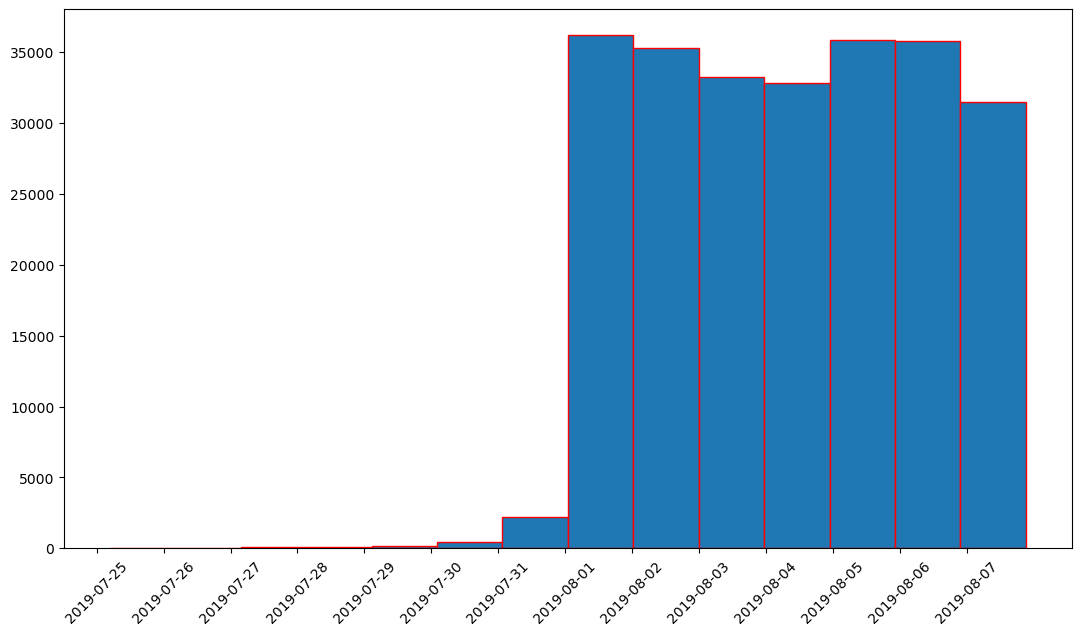

In [ ]:
eventos['momento_evento'].hist(bins=14, figsize=(13,7), xrot=45, edgecolor='red', grid=False)

_ = plt.xticks(pd.date_range(start='2019-07-25', end='2019-08-07', freq='D'))

In [ ]:
eventos_segmentado = eventos[eventos['momento_evento'] >= '2019-08-01']

eventos_segmentado.info()
print()
print(eventos_segmentado.head())

<class 'pandas.DataFrame'>
Index: 240887 entries, 2828 to 244125
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype        
---  ------          --------------   -----        
 0   nombre_evento   240887 non-null  str          
 1   id_dispositivo  240887 non-null  int64        
 2   momento_evento  240887 non-null  datetime64[s]
 3   id_experimento  240887 non-null  int64        
 4   fecha           240887 non-null  object       
dtypes: datetime64[s](1), int64(2), object(1), str(1)
memory usage: 9.2+ MB

           nombre_evento       id_dispositivo      momento_evento  \
2828            Tutorial  3737462046622621720 2019-08-01 00:07:28   
2829    MainScreenAppear  3737462046622621720 2019-08-01 00:08:00   
2830    MainScreenAppear  3737462046622621720 2019-08-01 00:08:55   
2831  OffersScreenAppear  3737462046622621720 2019-08-01 00:08:58   
2832    MainScreenAppear  1433840883824088890 2019-08-01 00:08:59   

      id_experimento       fecha  
2828        

Validamos que los datos originales abarcan del 25/07/2019 al 07/08/2019 (14 días). En el histograma se aprecia una clara concentración de eventos en los últimos 7 días, mientras que los primeros 7 presentan un volumen prácticamente nulo por registros residuales. Por ello, se descartan esos primeros días y se ajusta el análisis únicamente a la información completa. Con este filtro, los datos a analizar representan formalmente el periodo del 01/08/2019 al 07/08/2019 (7 días completos).

In [ ]:
print(len(eventos_segmentado['id_dispositivo'].unique()))

7534


En términos de volumen, pasamos de 243,713 a 240,887 eventos, descartando únicamente 2,826 filas (1.16% del total). Respecto a los usuarios, pasamos de 7,551 a 7,534 usuarios únicos, perdiendo tan solo 17 usuarios (0.23%).

In [ ]:
print(eventos_segmentado.groupby('id_experimento')['id_dispositivo'].nunique())

id_experimento
246    2484
247    2513
248    2537
Name: id_dispositivo, dtype: int64


Finalmente, confirmamos que los tres grupos experimentales conservan una presencia sólida y equilibrada (~33% cada uno). El Grupo 246 (Control 1) mantiene 2,484 usuarios (32.97%), el Grupo 247 (Control 2) 2,513 usuarios (33.36%) y el Grupo 248 (Prueba) 2,537 usuarios (33.67%), representando los grupos de control en conjunto 4,997 usuarios (66.33%).

## 4. Análisis del embudo de conversión

In [ ]:
print(eventos_segmentado['nombre_evento'].value_counts())

nombre_evento
MainScreenAppear           117328
OffersScreenAppear          46333
CartScreenAppear            42303
PaymentScreenSuccessful     33918
Tutorial                     1005
Name: count, dtype: int64


El análisis abarca 5 eventos clave: pantalla principal, pantalla de ofertas, pantalla del carrito, pantalla de pago y tutorial. Con 117 328 registros, la pantalla principal concentra el mayor volumen de actividad. En contraste, el tutorial registra únicamente 1 005 eventos, lo cual refleja su carácter opcional dentro del flujo de la aplicación.

In [ ]:
accion_por_usuario = eventos_segmentado.groupby('nombre_evento')['id_dispositivo'].nunique().sort_values(ascending=False)

usuarios_unicos = len(eventos_segmentado['id_dispositivo'].unique())

print('Acciones por usuario: ', accion_por_usuario)
print()
print('Proporción de usuarios: ', ((accion_por_usuario / usuarios_unicos) * 100))

Acciones por usuario:  nombre_evento
MainScreenAppear           7419
OffersScreenAppear         4593
CartScreenAppear           3734
PaymentScreenSuccessful    3539
Tutorial                    840
Name: id_dispositivo, dtype: int64

Proporción de usuarios:  nombre_evento
MainScreenAppear           98.473586
OffersScreenAppear         60.963632
CartScreenAppear           49.561986
PaymentScreenSuccessful    46.973719
Tutorial                   11.149456
Name: id_dispositivo, dtype: float64


Del total de usuarios únicos (7,534), el 98.47% (7,419) ingresó a la pantalla principal, el 60.96% (4,593) avanzó a la pantalla de ofertas, el 49.56% (3,734) llegó al carrito de compras, el 46.97% (3,539) completó el pago exitosamente y solo el 11.15% (840) realizó el tutorial.

Las acciones del proceso de compra ocurren en la siguiente secuencia lineal:

1. Pantalla Principal (MainScreenAppear)
2. Pantalla de Ofertas (OffersScreenAppear)
3. Pantalla del Carrito (CartScreenAppear)
4. Pantalla de Pago (PaymentScreenSuccessful)

El evento Tutorial es una acción opcional que los usuarios pueden realizar o saltarse en cualquier momento sin interrumpir el flujo de compra, por lo que no forma parte del embudo principal y se excluye de este análisis.

Este orden se justifica tanto de forma lógica (el flujo habitual de un usuario en la aplicación) como estadística (presenta un volumen de eventos estrictamente descendente).

In [ ]:
pantalla_principal = accion_por_usuario.loc['MainScreenAppear']
pantalla_ofertas = accion_por_usuario.loc['OffersScreenAppear']
pantalla_carrito = accion_por_usuario.loc['CartScreenAppear']
pantalla_pago = accion_por_usuario.loc['PaymentScreenSuccessful']

print('De Principal a Ofertas: ', ((pantalla_ofertas / pantalla_principal) * 100))
print()
print('De Ofertas a Carrito: ', ((pantalla_carrito / pantalla_ofertas) * 100))
print()
print('De Carrito a Pago: ', ((pantalla_pago / pantalla_carrito) * 100))
print()
print('Usuarios de inicio a fin: ', ((pantalla_pago / pantalla_principal) * 100))

De Principal a Ofertas:  61.908613020622724

De Ofertas a Carrito:  81.29762682342695

De Carrito a Pago:  94.7777182645956

Usuarios de inicio a fin:  47.70184661005526


Se construye el embudo de eventos para calcular la tasa de conversión entre etapas consecutivas. La etapa donde se pierde la mayor cantidad de usuarios es en la primera transición (de la pantalla principal a la pantalla de ofertas), ya que la retención cae al 61.91% (una pérdida del 38.09%).

En las etapas posteriores, el flujo muestra una retención significativamente mayor: la transición de la pantalla de ofertas al carrito alcanza el 81.30%, mientras que del carrito a la confirmación de pago llega al 94.78%.

En conjunto, el 47.70% de los usuarios realiza todo el recorrido desde la pantalla principal hasta completar el pago exitosamente.

## 5. Análisis del experimento A/A/B

In [ ]:
usuarios_por_grupo = (
    eventos_segmentado
    .groupby('id_dispositivo')['id_experimento']
    .nunique()
)

usuarios_multiples_grupos = (usuarios_por_grupo > 1).sum()

print(
    f'Usuarios presentes en más de un grupo experimental: '
    f'{usuarios_multiples_grupos}'
)

Usuarios presentes en más de un grupo experimental: 0


### Validación de la asignación experimental

Se verificó que cada usuario perteneciera únicamente a un grupo experimental. No se identificaron usuarios presentes simultáneamente en más de un grupo, por lo que no existe contaminación entre las muestras utilizadas para las comparaciones A/A/B.

In [ ]:
print(eventos_segmentado.groupby('id_experimento')['id_dispositivo'].nunique())

id_experimento
246    2484
247    2513
248    2537
Name: id_dispositivo, dtype: int64


Los tres grupos experimentales conservan una presencia sólida y equilibrada (~33% cada uno). El Grupo 246 (Control 1) mantiene 2,484 usuarios (32.97%), el Grupo 247 (Control 2) 2,513 usuarios (33.36%) y el Grupo 248 (Prueba) 2,537 usuarios (33.67%), representando los grupos de control en conjunto 4,997 usuarios (66.33%).

In [ ]:
resumen_experimentos = eventos_segmentado.pivot_table(index='nombre_evento', columns='id_experimento', values='id_dispositivo', aggfunc='nunique')

print(resumen_experimentos)
print()

totales_control = [2484, 2513]
alpha = 0.05

print("=== PRUEBA DE HIPÓTESIS: TEST A/A (246 vs 247) ===\n")

for evento in resumen_experimentos.index:
    exitos = [
        resumen_experimentos.loc[evento, 246],
        resumen_experimentos.loc[evento, 247],
    ]

    stat, p_value = proportions_ztest(count=exitos, nobs=totales_control)

    print(f"Evento: {evento}")
    print(f"  p-value: {p_value:.4f}")

    if p_value < alpha:
        print(
            "  -> Resultado: Diferencia SIGNIFICATIVA (Se rechaza H0). El test"
            " A/A presenta sesgo.\n"
        )
    else:
        print(
            "  -> Resultado: No hay diferencia significativa (No se rechaza"
            " H0). El test A/A es VÁLIDO.\n"
        )

id_experimento            246   247   248
nombre_evento                            
CartScreenAppear         1266  1238  1230
MainScreenAppear         2450  2476  2493
OffersScreenAppear       1542  1520  1531
PaymentScreenSuccessful  1200  1158  1181
Tutorial                  278   283   279

=== PRUEBA DE HIPÓTESIS: TEST A/A (246 vs 247) ===

Evento: CartScreenAppear
  p-value: 0.2288
  -> Resultado: No hay diferencia significativa (No se rechaza H0). El test A/A es VÁLIDO.

Evento: MainScreenAppear
  p-value: 0.7571
  -> Resultado: No hay diferencia significativa (No se rechaza H0). El test A/A es VÁLIDO.

Evento: OffersScreenAppear
  p-value: 0.2481
  -> Resultado: No hay diferencia significativa (No se rechaza H0). El test A/A es VÁLIDO.

Evento: PaymentScreenSuccessful
  p-value: 0.1146
  -> Resultado: No hay diferencia significativa (No se rechaza H0). El test A/A es VÁLIDO.

Evento: Tutorial
  p-value: 0.9377
  -> Resultado: No hay diferencia significativa (No se rechaza H0). E

In [ ]:
totales_usuarios = {246: 2484, 247: 2513, 248: 2537}

def evaluar_diferencia_proporciones(
    grupo_1,
    grupo_2,
    resumen=resumen_experimentos,
    totales=totales_usuarios,
    alpha=0.05,
):
    print(
        f"=================================================="
        f"\nPRUEBA Z DE PROPORCIONES: GRUPO {grupo_1} vs GRUPO {grupo_2}"
        f"\n=================================================="
    )
    resumen_ordenado = resumen.loc[
        resumen.sum(axis=1).sort_values(ascending=False).index
    ]

    nobs = [totales[grupo_1], totales[grupo_2]]

    for evento in resumen_ordenado.index:
        count = [
            resumen_ordenado.loc[evento, grupo_1],
            resumen_ordenado.loc[evento, grupo_2],
        ]

        prop_1 = count[0] / nobs[0]
        prop_2 = count[1] / nobs[1]

        stat, p_value = proportions_ztest(count=count, nobs=nobs)

        print(f"\nEvento: {evento}")
        print(f"  • Grupo {grupo_1}: {prop_1:.2%} ({count[0]}/{nobs[0]})")
        print(f"  • Grupo {grupo_2}: {prop_2:.2%} ({count[1]}/{nobs[1]})")
        print(f"  • p-value: {p_value:.4f}")

        if p_value < alpha:
            print("  -> Resultado: Diferencia SIGNIFICATIVA (Se rechaza H0)")
        else:
            print(
                "  -> Resultado: No hay diferencia significativa (No se rechaza"
                " H0)"
            )

evaluar_diferencia_proporciones(246, 247)

PRUEBA Z DE PROPORCIONES: GRUPO 246 vs GRUPO 247

Evento: MainScreenAppear
  • Grupo 246: 98.63% (2450/2484)
  • Grupo 247: 98.53% (2476/2513)
  • p-value: 0.7571
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: OffersScreenAppear
  • Grupo 246: 62.08% (1542/2484)
  • Grupo 247: 60.49% (1520/2513)
  • p-value: 0.2481
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: CartScreenAppear
  • Grupo 246: 50.97% (1266/2484)
  • Grupo 247: 49.26% (1238/2513)
  • p-value: 0.2288
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: PaymentScreenSuccessful
  • Grupo 246: 48.31% (1200/2484)
  • Grupo 247: 46.08% (1158/2513)
  • p-value: 0.1146
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: Tutorial
  • Grupo 246: 11.19% (278/2484)
  • Grupo 247: 11.26% (283/2513)
  • p-value: 0.9377
  -> Resultado: No hay diferencia significativa (No se rechaza H0)


El evento más popular es MainScreenAppear, alcanzando un 98.63% de usuarios en el Grupo 246 y un 98.53% en el Grupo 247.

Al no existir diferencias estadísticamente significativas entre los dos grupos de control, se confirma que los usuarios se dividieron correctamente y que el mecanismo de segmentación opera de forma homogénea sin sesgos iniciales.

In [ ]:
evaluar_diferencia_proporciones(246, 248)

evaluar_diferencia_proporciones(247, 248)

PRUEBA Z DE PROPORCIONES: GRUPO 246 vs GRUPO 248

Evento: MainScreenAppear
  • Grupo 246: 98.63% (2450/2484)
  • Grupo 248: 98.27% (2493/2537)
  • p-value: 0.2950
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: OffersScreenAppear
  • Grupo 246: 62.08% (1542/2484)
  • Grupo 248: 60.35% (1531/2537)
  • p-value: 0.2084
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: CartScreenAppear
  • Grupo 246: 50.97% (1266/2484)
  • Grupo 248: 48.48% (1230/2537)
  • p-value: 0.0784
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: PaymentScreenSuccessful
  • Grupo 246: 48.31% (1200/2484)
  • Grupo 248: 46.55% (1181/2537)
  • p-value: 0.2123
  -> Resultado: No hay diferencia significativa (No se rechaza H0)

Evento: Tutorial
  • Grupo 246: 11.19% (278/2484)
  • Grupo 248: 11.00% (279/2537)
  • p-value: 0.8264
  -> Resultado: No hay diferencia significativa (No se rechaza H0)
PRUEBA Z DE PROPORCIONES: GRUPO 247 vs GRUPO 24

El evento más popular en el Grupo 248 sigue siendo MainScreenAppear, alcanzando al 98.27% de sus usuarios.

Al evaluar las pruebas A/B comparando el grupo de prueba (248) frente a cada grupo de control de forma independiente (246 vs 248 y 247 vs 248), no se detectaron diferencias estadísticamente significativas en ninguno de los eventos analizados.

Con base en los datos del experimento, no existe evidencia estadística de que el cambio de fuentes tipográficas haya modificado las tasas de conversión observadas. Por lo tanto, los resultados no muestran un efecto negativo ni positivo significativo asociado al nuevo diseño.

In [ ]:
resumen_experimentos['246+247'] = (
    resumen_experimentos[246] + resumen_experimentos[247]
)
totales_usuarios['246+247'] = totales_usuarios[246] + totales_usuarios[247]

comparaciones = [(246, 247), (246, 248), (247, 248), ('246+247', 248)]

eventos = resumen_experimentos.index
total_pruebas = len(comparaciones) * len(eventos)

alpha_base = 0.05
alpha_bonferroni = alpha_base / total_pruebas

print(f'Total de pruebas de hipótesis realizadas: {total_pruebas}')
print(f'Nivel de significancia original (alpha): {alpha_base}')
print(f'Nivel de significancia corregido (Bonferroni): {alpha_bonferroni:.4f}\n')

for g1, g2 in comparaciones:
    nobs = [totales_usuarios[g1], totales_usuarios[g2]]
    print(
        f'==================================================\nCOMPARACIÓN:'
        f' GRUPO {g1} vs GRUPO {g2}\n=================================================='
    )

    for evento in eventos:
        count = [
            resumen_experimentos.loc[evento, g1],
            resumen_experimentos.loc[evento, g2],
        ]

        stat, p_value = proportions_ztest(count=count, nobs=nobs)

        sig_base = p_value < alpha_base
        sig_bonf = p_value < alpha_bonferroni

        print(f'Evento: {evento}')
        print(f'  • p-value: {p_value:.4f}')
        print(
            f"  • Alpha 0.05: {'Diferencia significativa' if sig_base else 'No hay diferencia'}"
        )
        print(
            f"  • Bonferroni ({alpha_bonferroni:.4f}):"
            f" {'Diferencia significativa' if sig_bonf else 'No hay diferencia'}\n"
        )

Total de pruebas de hipótesis realizadas: 20
Nivel de significancia original (alpha): 0.05
Nivel de significancia corregido (Bonferroni): 0.0025

COMPARACIÓN: GRUPO 246 vs GRUPO 247
Evento: CartScreenAppear
  • p-value: 0.2288
  • Alpha 0.05: No hay diferencia
  • Bonferroni (0.0025): No hay diferencia

Evento: MainScreenAppear
  • p-value: 0.7571
  • Alpha 0.05: No hay diferencia
  • Bonferroni (0.0025): No hay diferencia

Evento: OffersScreenAppear
  • p-value: 0.2481
  • Alpha 0.05: No hay diferencia
  • Bonferroni (0.0025): No hay diferencia

Evento: PaymentScreenSuccessful
  • p-value: 0.1146
  • Alpha 0.05: No hay diferencia
  • Bonferroni (0.0025): No hay diferencia

Evento: Tutorial
  • p-value: 0.9377
  • Alpha 0.05: No hay diferencia
  • Bonferroni (0.0025): No hay diferencia

COMPARACIÓN: GRUPO 246 vs GRUPO 248
Evento: CartScreenAppear
  • p-value: 0.0784
  • Alpha 0.05: No hay diferencia
  • Bonferroni (0.0025): No hay diferencia

Evento: MainScreenAppear
  • p-value: 0.295

Inicialmente se estableció un nivel de significación del 5% y se realizaron 20 pruebas de hipótesis estadísticas en total (4 comparaciones entre grupos × 5 eventos).

Para controlar el riesgo de falsos positivos asociado a la realización de múltiples pruebas, se aplicó la corrección de Bonferroni, ajustando el nivel de significación a **0.0025 (0.25%)**.

Al reevaluar los resultados bajo este criterio más estricto, ninguna prueba mostró diferencias estadísticamente significativas.

Por lo tanto, los resultados del experimento no proporcionan evidencia de que el cambio de fuentes tipográficas produzca diferencias significativas en las tasas de conversión de los eventos analizados.

## 6. Conclusiones

### Embudo de conversión

El análisis del comportamiento de 7,534 usuarios permitió identificar el flujo principal de navegación de la aplicación: pantalla principal → ofertas → carrito → pago.

El principal punto de abandono ocurre entre la pantalla principal y la pantalla de ofertas, donde la retención es del **61.91%**, equivalente a una pérdida aproximada del **38.09%** de los usuarios.

Las etapas posteriores presentan tasas de retención superiores: **81.30%** de ofertas a carrito y **94.78%** de carrito a pago.

En conjunto, aproximadamente el **47.70%** de los usuarios que ingresan a la pantalla principal completan el proceso hasta el pago.

### Experimento A/A/B

La comparación entre los grupos de control 246 y 247 no mostró diferencias estadísticamente significativas en los eventos analizados, lo que respalda la consistencia de la segmentación utilizada en el experimento.

Posteriormente, las comparaciones del grupo experimental 248 frente a cada grupo de control tampoco mostraron diferencias estadísticamente significativas.

Se realizaron **20 pruebas de hipótesis** y se aplicó la corrección de Bonferroni, reduciendo el nivel de significación de 0.05 a **0.0025** para controlar el riesgo de falsos positivos asociado a comparaciones múltiples. Las conclusiones se mantuvieron bajo este criterio.

### Conclusión de negocio

Los resultados no proporcionan evidencia estadística de que el cambio de fuentes tipográficas genere diferencias significativas en el comportamiento o en la conversión de los usuarios.

Por otra parte, el embudo de conversión muestra que la principal oportunidad de mejora se encuentra en la transición entre la pantalla principal y la pantalla de ofertas, donde se concentra la mayor pérdida de usuarios.